## Introduction

The purpose of this document is to compare the performance of operations in *RGB* colourspaces against a spectral reference.

In an *RGB* colourspace, the basis vectors are defined by the primaries. Mathematical operations are dependent on the chosen basis vectors. As an example, a triplet of *tristimulus values*, converted to values in three different *RGB* colourspaces, subsequently *exponentiated*, and converted back to the *CIE XYZ* colourspace will produce different triplets of *tristimulus values*, one for each of the three *RGB* colourspaces. In this context, the result of the *multiplication*, *division* and *power* operations is dependent on the *RGB* colourspace primaries, producing three different final triplets of *tristimulus values* while *addition* and *subtraction* operations would produce three equal triplets of *tristimulus values*.

The *rgb_colourspace_primaries_dependency* definition below demonstrates this behaviour: Two colours are selected from the colour rendition chart. They are then used as operands for different operations happening respectively in *sRGB* and *Rec. 2020* colourspaces. The two resulting colours are then converted back to *CIE XYZ* colourspace and compared.

> Note: A companion spreadsheet is available at the following URL: http://goo.gl/akrH5m

<!-- TEASER_END -->

In [1]:
import operator
from pprint import pprint

import colour


def rgb_colourspace_primaries_dependency(operator=operator.add):
    name, data, illuminant = colour.COLOURCHECKERS['ColorChecker 2005']

    # Aliases for *sRGB* colourspace.
    sRGB_w = colour.sRGB_COLOURSPACE.whitepoint
    sRGB_XYZ_to_RGB = colour.sRGB_COLOURSPACE.XYZ_to_RGB_matrix
    sRGB_RGB_to_XYZ = colour.sRGB_COLOURSPACE.RGB_to_XYZ_matrix

    # Aliases for *Rec. 2020* colourspace.
    REC_2020_w = colour.REC_2020_COLOURSPACE.whitepoint
    REC_2020_XYZ_to_RGB = colour.REC_2020_COLOURSPACE.XYZ_to_RGB_matrix
    REC_2020_RGB_to_XYZ = colour.REC_2020_COLOURSPACE.RGB_to_XYZ_matrix

    # Selecting various colours from the colour rendition chart:
    # *Dark Skin*
    _, _, x, y, Y = data[0]
    XYZ_r1 = colour.xyY_to_XYZ((x, y, Y))
    # *Green*
    _, _, x, y, Y = data[13]
    XYZ_r2 = colour.xyY_to_XYZ((x, y, Y))

    # Defining the *sRGB* *Dark Skin* colour.
    sRGB_r1 = colour.XYZ_to_RGB(XYZ_r1,
                                illuminant,
                                sRGB_w,
                                sRGB_XYZ_to_RGB)

    # Defining the *sRGB* *Green* colour.
    sRGB_r2 = colour.XYZ_to_RGB(XYZ_r2,
                                illuminant,
                                sRGB_w,
                                sRGB_XYZ_to_RGB)

    # Performing *sRGB* *Dark Skin* and *Green* colours operation.
    sRGB_m = operator(sRGB_r1, sRGB_r2)

    # Converting resulting colour to *CIE* *XYZ* colourspace.
    XYZ_sRGB_m1 = colour.RGB_to_XYZ(sRGB_m,
                                    sRGB_w,
                                    illuminant,
                                    sRGB_RGB_to_XYZ)

    # Defining the *Rec. 2020* *Dark Skin* colour.
    REC_2020_r1 = colour.XYZ_to_RGB(XYZ_r1,
                                    illuminant,
                                    REC_2020_w,
                                    REC_2020_XYZ_to_RGB)

    # Defining the *Rec. 2020* *Green* colour.
    REC_2020_r2 = colour.XYZ_to_RGB(XYZ_r2,
                                    illuminant,
                                    REC_2020_w,
                                    REC_2020_XYZ_to_RGB)

    # Performing the *Rec. 2020* *Dark Skin* and *Green* colours operation.
    REC_2020_m = operator(REC_2020_r1, REC_2020_r2)

    # Converting resulting colour to *CIE* *XYZ* colourspace.
    XYZ_REC_2020_m1 = colour.RGB_to_XYZ(REC_2020_m,
                                        REC_2020_w,
                                        illuminant,
                                        REC_2020_RGB_to_XYZ)

    return (XYZ_sRGB_m1, XYZ_REC_2020_m1)


for operator in (operator.add,
                 operator.sub,
                 operator.mul,
                 operator.div,
                 operator.pow):
    print('{0}:'.format(operator.__name__))
    pprint(rgb_colourspace_primaries_dependency(operator))
    print('\n')

add:
(array([ 0.26503479,  0.3326    ,  0.12989551]),
 array([ 0.26503479,  0.3326    ,  0.12989551]))


sub:
(array([-0.03466529, -0.131     , -0.02810806]),
 array([-0.03466529, -0.131     , -0.02810806]))


mul:
(array([ 0.01419744,  0.02001609,  0.00525311]),
 array([ 0.01744617,  0.02218764,  0.00496058]))


div:
(array([ 1.60211763,  0.94783487,  0.64260732]),
 array([ 0.81894892,  0.5243635 ,  0.54464893]))


pow:
(array([ 0.69403138,  0.58944147,  0.64315778]),
 array([ 0.69452189,  0.58949601,  0.63399593]))




## Methodology

We have decided to test *multiplication* operation because it is affected by *RGB* colourspace primaries dependencies and especially because it is easily possible to design synthetic spectral power distributions that can be applied on existing spectral data, like the one from a colour rendition chart and also on the same data converted to *RGB* upon conversion to tristimulus values.

In early versions of this document, the synthetic spectral power distributions were named *filters* as they were designed to mimic existing filter sets from real life. However, we discovered that referencing existing real life *filters* was introducing an important bias in the results. We were basically finding the best colourspace for a given set of filters thus we decided to change the *filters* design so that we have a very large amount of different synthetic spectral power distributions.

The methodology implementation code is available in the [Process](#Process) section and is illustrated in the following figure:

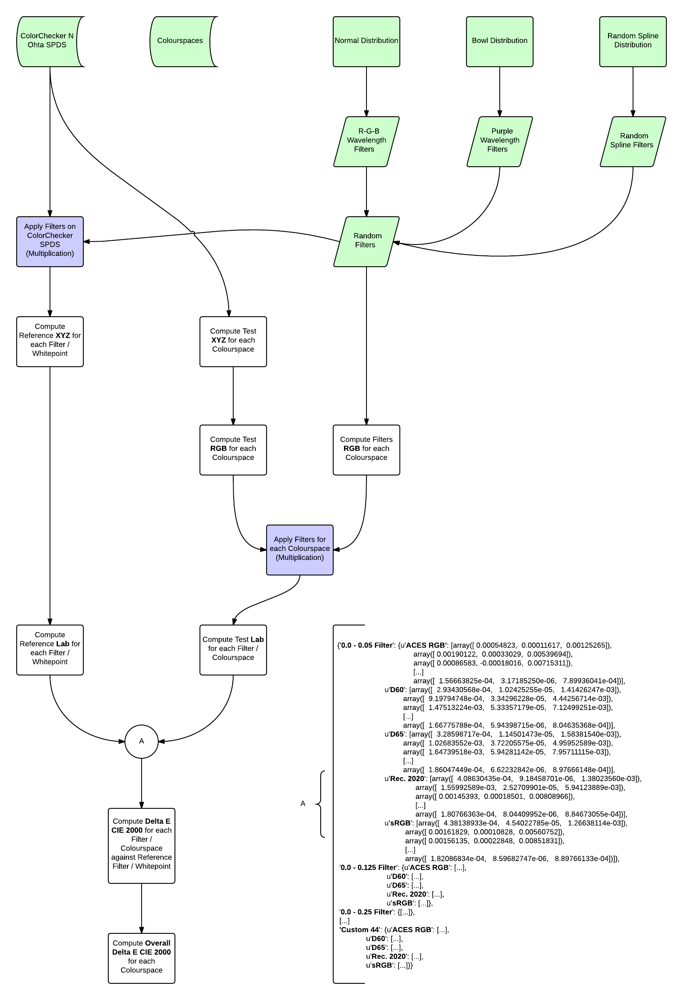

In [2]:
from IPython.core.display import Image

Image(filename="resources/images/About Colourspaces & Colour Rendition Charts - Overall.png")

The spectral test data is coming from *N. Ohta Colour Rendition Chart Classic* and *X-Rite Colour Rendition Chart SG* colour rendition charts.

The filters design will be detailed in the [Filters Design](#Filters-Design) section but let's assume that we have a large number of random spectral power distributions providing coverage of the spectral locus.

Picking a test sample, a random filter and an *RGB* colourspace model, we follow two paths:

- The first path is the spectral path where the test sample is weighted by the random filter and then converted to tristimulus values under the *RGB* colourspace model illuminant. The tristimulus values are then converted to *CIE Lab* and labeled as the *Reference Lab* matrix.
- The second path is the *RGB* path where the test sample and the random filter are converted to tristimulus values under the *RGB* colourspace model illuminant, then respectively converted to *RGB*. The test sample *RGB* triplet is then weighted by the random filter *RGB* triplet. The resulting *RGB* triplet is also converted to *CIE Lab* and labeled as the *Test Lab* matrix.

$\Delta_{E_{ab}}$ *CIE 2000* colour difference is then computed with the *Reference Lab* and *Test Lab* matrices. 

This process is repeated for each sample, each random filter and each *RGB* colourspace. The resulting $\Delta_{E_{ab}}$ values are averaged together to get an overall value for each *RGB* colourspace. We also take that opportunity to compute standard deviation $\sigma$ and min / max $\Delta_{E_{ab}}$ values for each *RGB* colourspace.

## Filters Design

In order to improve upon earlier versions, the filters are now quasi-randomly generated. We have defined 3 base distributions as follows:

- *Normal* distribution: A basic normal distribution that can be centered on an arbitrary wavelength.
- *Bowl* distribution: A distribution with the shape of a bowl and that can be centered on an arbitrary wavelength. Its purpose is to provide coverage for the spectral locus line of purples that cannot be reached using a normal distribution.
- *Random Spline* distribution: This distribution is used to generate random spline distributions with very few points.

From the base distributions the filters are designed:

- The first step is to generate the initial filters using the *Normal* and *Bowl* distributions, the wavelengths have been cherry-picked to provide coverage as evenly spaced as possible of the spectral locus boundaries as seen in the [Initial Spectral Power Distributions](#Initial-Spectral-Power-Distributions) section.
- We then start designing the final filters: the initial filters are randomly offset along the spectrum and averaged with a *Random Spline* distribution using ratio 0.85 / 0.15 in order to provide variation.
- The resulting set of filters is combined with a pool of pure *Random Spline* distributions with a 0.5 / 0.5 ratio. We label that pool of filters *Random Filters*.
- The *Random Filters* are then saturated to regain spectral locus coverage. The ratio is 1/3 default *Random Filters*, 1/3 square saturated *Random Filters*, 1/3 cubic saturated *Random Filters*.
- The *Random Filters* are checked for uniqueness and almost-equal ones are discarded.

The *Random Filters* can be seen in the [Random Filters - Design](#Random-Filters---Design) section and their design process is illustrated in the figure below:

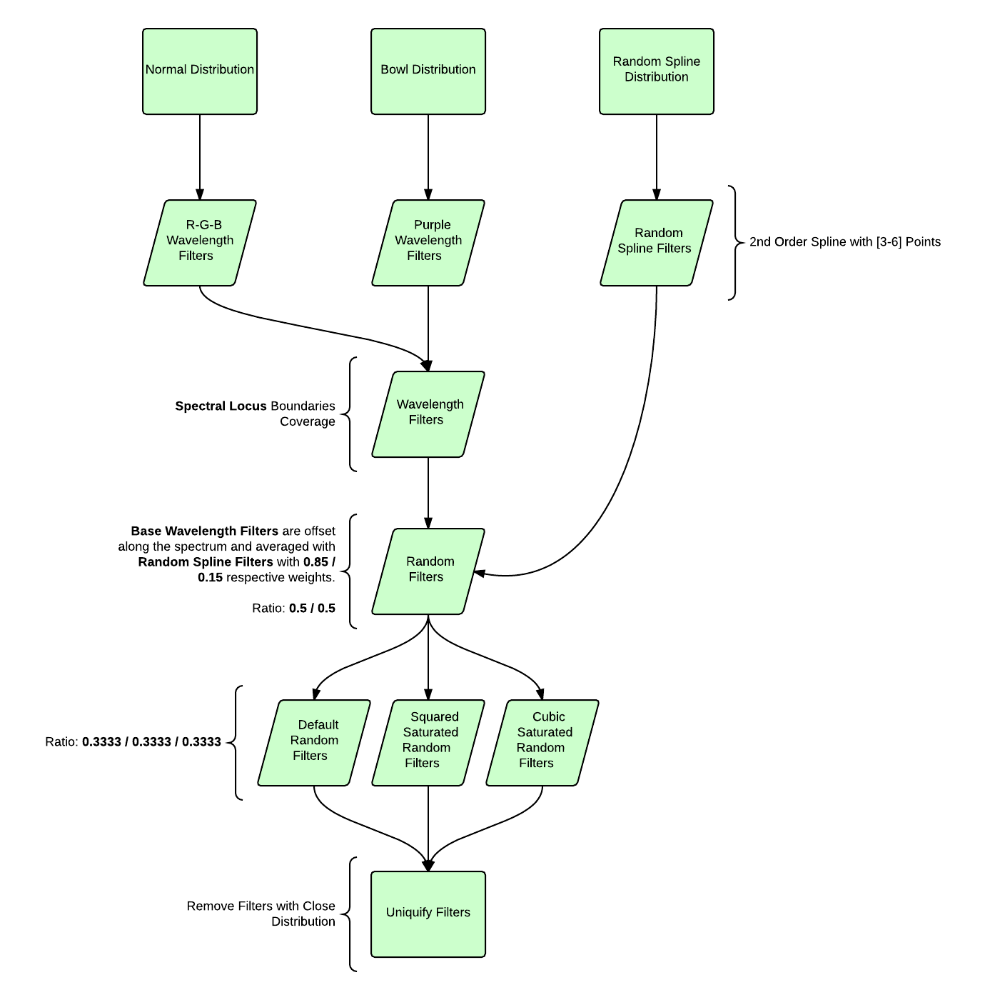

In [3]:
Image(filename="resources/images/About Colourspaces & Colour Rendition Charts - Filters Design.png")

## Implementation

### Colour Rendition Charts

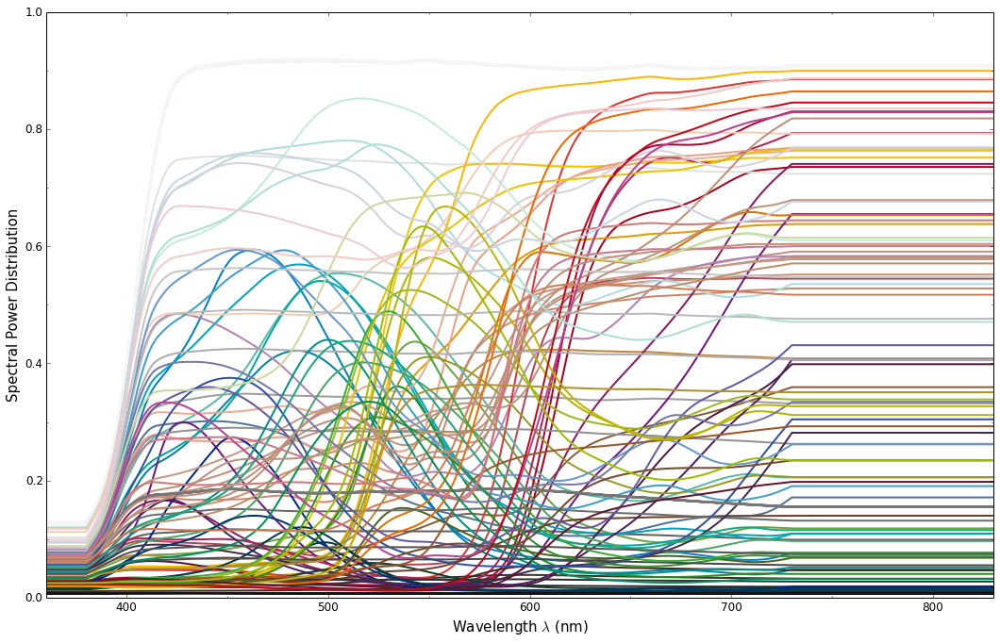

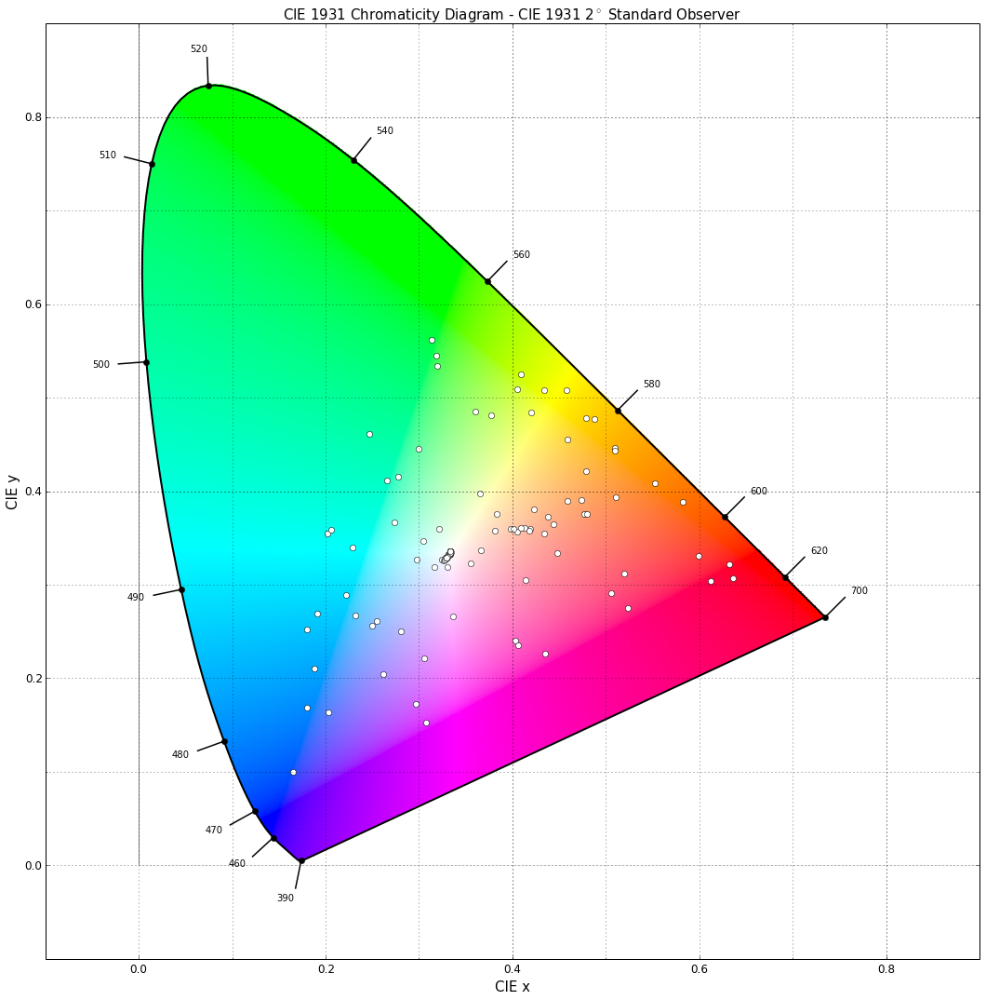

In [4]:
%matplotlib inline

import logging
reload(logging)

import matplotlib.pyplot
import numpy as np
import os
import pylab
import re
from IPython.display import HTML
from mpl_toolkits.mplot3d import Axes3D, art3d
from copy import deepcopy

from colour.characterisation.dataset.colour_checkers.spds import (
    COLOURCHECKER_INDEXES_TO_NAMES_MAPPING)
from colour.plotting import *

# Logging configuration.
LOGGER = logging.getLogger('colour-science')
LOGGER.setLevel(logging.DEBUG)

LOGGING_FILE = 'about_colourspaces_colour_rendition_charts.log'

os.path.exists(LOGGING_FILE) and os.remove(LOGGING_FILE)

HANDLER = logging.FileHandler(LOGGING_FILE)
HANDLER.setFormatter(logging.Formatter('%(asctime)s - %(levelname)-8s: %(message)s'))

LOGGER.addHandler(HANDLER) 

LOGGER.info('*' * 79)
LOGGER.info('About Colourspaces & Colour Rendition Charts')
LOGGER.info('*' * 79)

pylab.rcParams['figure.figsize'] = 28, 14

CMFS = colour.CMFS['CIE 1931 2 Degree Standard Observer']
SHAPE = CMFS.shape


def read_xrite_spds(path):
    xrite_reflectances_file = open(path)
    xrite_reflectances_data = xrite_reflectances_file.read().strip().split(
        '\n')

    xrite_spds = []
    is_spectral_data_format, is_spectral_data = False, False
    for line in xrite_reflectances_data:
        line = line.strip()

        if line == 'END_DATA_FORMAT':
            is_spectral_data_format = False

        if line == 'END_DATA':
            is_spectral_data = False

        if is_spectral_data_format:
            wavelengths = [float(x) for x in re.findall('nm(\d+)', line)]
            index = len(wavelengths)

        if is_spectral_data:
            tokens = line.split()
            values = [float(x) for x in tokens[-index:]]
            xrite_spds.append(colour.SpectralPowerDistribution(tokens[1],
                                                               dict(zip(
                                                                   wavelengths,
                                                                   values))))

        if line == 'BEGIN_DATA_FORMAT':
            is_spectral_data_format = True

        if line == 'BEGIN_DATA':
            is_spectral_data = True
    return xrite_spds


COLOUR_CHECKER = 'SG'

LOGGER.info('Colour checker: \'{0}\''.format(COLOUR_CHECKER))

if COLOUR_CHECKER == 'Classic':
    # Preparing N. Ohta Colour Rendition Chart Classic (24 samples).
    COLOUR_CHECKER = deepcopy(
        colour.COLOURCHECKERS_SPDS['ColorChecker N Ohta'])
    COLOUR_CHECKER_MAPPING = COLOURCHECKER_INDEXES_TO_NAMES_MAPPING
elif COLOUR_CHECKER == 'SG':
    # Preparing X-Rite Colour Rendition Chart SG (140 samples).
    xrite_spds = read_xrite_spds(
        'resources/others/Digital_ColorChecker_SG.txt')
    xrite_spds_names = [xrite_spd.name for xrite_spd in xrite_spds]
    xrite_spds_indexes = range(len(xrite_spds_names))
    COLOUR_CHECKER = dict(zip(xrite_spds_names, xrite_spds))
    COLOUR_CHECKER_MAPPING = dict(zip(xrite_spds_indexes, xrite_spds_names))

[spd.align(SHAPE) for spd in COLOUR_CHECKER.values()]


def get_colour_checker_spds(colour_checker=COLOUR_CHECKER,
                            mapping=COLOUR_CHECKER_MAPPING):
    spds = []
    for index, sample in sorted(mapping.items()):
        spds.append(colour_checker[sample].clone())
    return spds


# TODO: Merge in *colour*.
def spds_CIE_1931_chromaticity_diagram_plot(
        spds,
        cmfs='CIE 1931 2 Degree Standard Observer',
        annotate=True,
        **kwargs):
    CIE_1931_chromaticity_diagram_plot(standalone=False,
                                       **kwargs)

    cmfs, name = get_cmfs(cmfs), cmfs
    cmfs_shape = cmfs.shape

    for spd in spds:
        spd = spd.clone().align(cmfs_shape)
        XYZ = colour.spectral_to_XYZ(spd) / 100
        xy = colour.XYZ_to_xy(XYZ)

        pylab.plot(xy[0], xy[1], 'o', color='white')

        if spd.name is not None and annotate:
            pylab.annotate(spd.name,
                           xy=xy,
                           xytext=(50, 30),
                           textcoords='offset points',
                           arrowprops=dict(arrowstyle='->',
                                           connectionstyle='arc3, rad=0.2'))

    display(standalone=True)


def spds_CIE_1960_UCS_chromaticity_diagram_plot(
        spds,
        cmfs='CIE 1931 2 Degree Standard Observer',
        annotate=True,
        **kwargs):
    CIE_1960_UCS_chromaticity_diagram_plot(standalone=False,
                                           **kwargs)

    cmfs, name = get_cmfs(cmfs), cmfs
    cmfs_shape = cmfs.shape

    for spd in spds:
        spd = spd.clone().align(cmfs_shape)
        XYZ = colour.spectral_to_XYZ(spd) / 100
        uv = colour.UCS_to_uv(colour.XYZ_to_UCS(XYZ))

        pylab.plot(uv[0], uv[1], 'o', color='white')

        if spd.name is not None and annotate:
            pylab.annotate(spd.name,
                           xy=uv,
                           xytext=(50, 30),
                           textcoords='offset points',
                           arrowprops=dict(arrowstyle='->',
                                           connectionstyle='arc3, rad=0.2'))

    display(standalone=True)


def spds_CIE_1976_UCS_chromaticity_diagram_plot(
        spds,
        cmfs='CIE 1931 2 Degree Standard Observer',
        annotate=True,
        **kwargs):
    CIE_1976_UCS_chromaticity_diagram_plot(standalone=False,
                                           **kwargs)

    cmfs, name = get_cmfs(cmfs), cmfs
    cmfs_shape = cmfs.shape

    for spd in spds:
        spd = spd.clone().align(cmfs_shape)
        XYZ = colour.spectral_to_XYZ(spd) / 100
        uv = colour.Luv_to_uv(colour.XYZ_to_Luv(XYZ))

        pylab.plot(uv[0], uv[1], 'o', color='white')

        if spd.name is not None and annotate:
            pylab.annotate(spd.name,
                           xy=uv,
                           xytext=(50, 30),
                           textcoords='offset points',
                           arrowprops=dict(arrowstyle='->',
                                           connectionstyle='arc3, rad=0.2'))

    display(standalone=True)


multi_spd_plot(COLOUR_CHECKER.values(), legend=False, use_spds_colours=True)

spds_CIE_1931_chromaticity_diagram_plot(COLOUR_CHECKER.values(),
                                        annotate=False)

### Colourspaces

In [5]:
COLOURSPACES_T = [c for c in colour.RGB_COLOURSPACES.values()]

LOGGER.info('Colourspaces: \'{0}\''.format(
    ', '.join(sorted(c.name for c in COLOURSPACES_T))))

### Process

In [6]:
import numpy as np
import time
from collections import namedtuple

Statistics = namedtuple('Statistics',
                        ('average_delta_E',
                         'standard_deviation',
                         'domain',
                         'delta_E'))


def timeit(f):
    def timed(*args, **kw):
        ts = time.time()
        result = f(*args, **kw)
        te = time.time()

        print '%r took: %2.4f sec' % (f.__name__, te - ts)
        return result

    return timed


def spectral_to_XYZ(spds, colourspace):
    return [colour.spectral_to_XYZ(
        spd,
        illuminant=(
            colour.ILLUMINANTS_RELATIVE_SPDS[
                colourspace.illuminant])) / 100
            for spd in spds]


def spectral_to_RGB(spds, colourspace):
    XYZ = spectral_to_XYZ(spds, colourspace)

    return [colour.XYZ_to_RGB(
        x,
        colourspace.whitepoint,
        colourspace.whitepoint,
        colourspace.XYZ_to_RGB_matrix) for x in XYZ]


def apply_filter_spectral(spds, spd_f, colourspace):
    for spd in spds:
        spd *= spd_f

    return spectral_to_XYZ(spds, colourspace)


def apply_filter_RGB(spds, spd_f, colourspace):
    RGB = spectral_to_RGB(spds, colourspace)
    RGB_f = spectral_to_RGB([spd_f], colourspace)[0]

    RGB *= RGB_f

    XYZ = [colour.RGB_to_XYZ(x,
                             colourspace.whitepoint,
                             colourspace.whitepoint,
                             colourspace.RGB_to_XYZ_matrix) for x in RGB]
    return XYZ


@timeit
def apply_filters(filters,
                  colourspaces_t=COLOURSPACES_T,
                  colour_checker=COLOUR_CHECKER):
    XYZ = {}
    for filter in filters:
        XYZ[filter.name] = {}

        for colourspace_t in colourspaces_t:
            LOGGER.info(
                'Applying \'{0}\' filter in \'{1}\' colourspace.'.format(
                    filter.name, colourspace_t.name))
            if not XYZ[filter.name].get(colourspace_t.illuminant):
                XYZ_r = apply_filter_spectral(
                    get_colour_checker_spds(colour_checker),

                    filter,
                    colourspace_t)
                XYZ[filter.name][colourspace_t.illuminant] = XYZ_r

            XYZ_c = apply_filter_RGB(
                get_colour_checker_spds(colour_checker),
                filter,
                colourspace_t)

            XYZ[filter.name][colourspace_t.name] = XYZ_c
    return XYZ


def XYZ_to_Lab(XYZ, colourspace):
    Lab = [colour.XYZ_to_Lab(x, colourspace.whitepoint) for x in XYZ]
    return Lab


@timeit
def filters_statistics(XYZ, colourspaces_t=COLOURSPACES_T):
    filters_statistics = {}
    for filter, XYZ_f in XYZ.items():
        filters_statistics[filter] = {}

        for colourspace_t in colourspaces_t:
            LOGGER.info(
                ('Computing \'{0}\' filter statistics for \'{1}\' '
                 'colourspace.').format(
                    filter, colourspace_t.name))
            Lab_r = XYZ_to_Lab(XYZ_f[colourspace_t.illuminant], colourspace_t)
            Lab = XYZ_to_Lab(XYZ_f[colourspace_t.name], colourspace_t)
            delta_E = [colour.delta_E_CIE2000(Lab_r[i], Lab[i])
                       for i in range(len(Lab_r))]
            filters_statistics[filter][colourspace_t.name] = Statistics(
                np.average(delta_E),
                np.std(delta_E),
                (np.min(delta_E), np.max(delta_E)),
                delta_E)
    return filters_statistics


def overall_statistics(filter_delta_E, colourspaces_t=COLOURSPACES_T):
    overall_statistics = {}
    for colourspace_t in colourspaces_t:
        overall_statistics[colourspace_t.name] = []

        for statistics in filter_delta_E.values():
            overall_statistics[colourspace_t.name].append(
                statistics[colourspace_t.name][0])

        colourspace_statistics = overall_statistics[colourspace_t.name]
        overall_statistics[colourspace_t.name] = Statistics(
            np.average(colourspace_statistics),
            np.std(colourspace_statistics),
            (np.min(colourspace_statistics), np.max(colourspace_statistics)),
            colourspace_statistics)
    return overall_statistics


def print_overall_statistics(filters_statistics):
    for colourspace, statistics in sorted(overall_statistics(
            filters_statistics).items(), key=lambda x: x[1]):
        print('{0}: ΔE: {1}, σ: {2}, ΔE Domain: {3}'.format(
            colourspace,
            statistics.average_delta_E,
            statistics.standard_deviation,
            statistics.domain))


def html_format_overall_statistics(filters_statistics, precision=7):
    html = ('<table>'
            '<tr>'
            '<th>Colourspace</th>'
            '<th>ΔE</th>'
            '<th>σ</th>'
            '<th>ΔE Domain</th>'
            '</tr>')

    pretty = lambda x: '{{: 0.{}f}}'.format(precision).format(x)

    for colourspace, statistics in sorted(overall_statistics(
            filters_statistics).items(), key=lambda x: x[1]):
        html += '<tr>'
        html += '<td class="font-bold">{0}</td>'.format(colourspace)
        html += '<td>{0}</td>'.format(pretty(statistics.average_delta_E, ))
        html += '<td>{0}</td>'.format(pretty(statistics.standard_deviation, ))
        html += ('<td><table><tr><td>{0}</td>'
                 '<td>{1}</td></tr></table></td>').format(
            *map(pretty, statistics.domain))
        html += '</tr>'
    html += '</table>'
    return html

## Filters - Design

### Initial Spectral Power Distributions

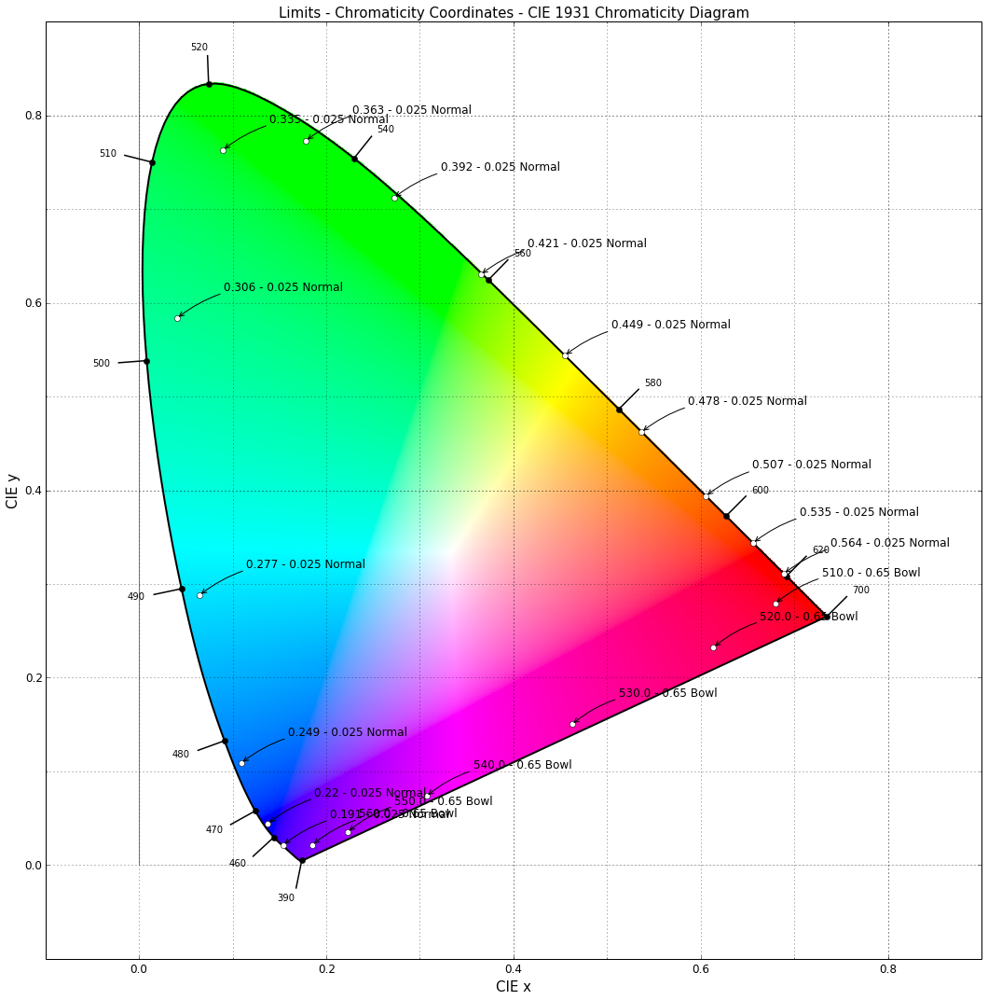

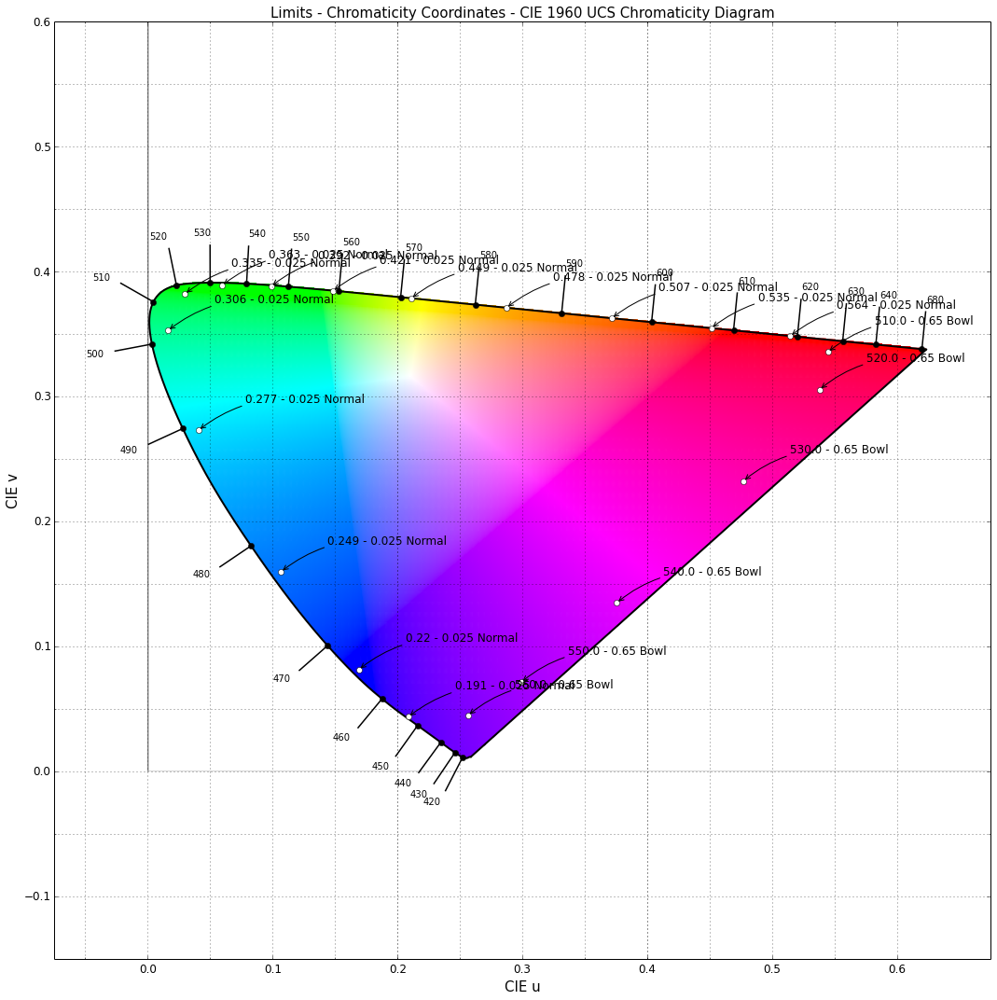

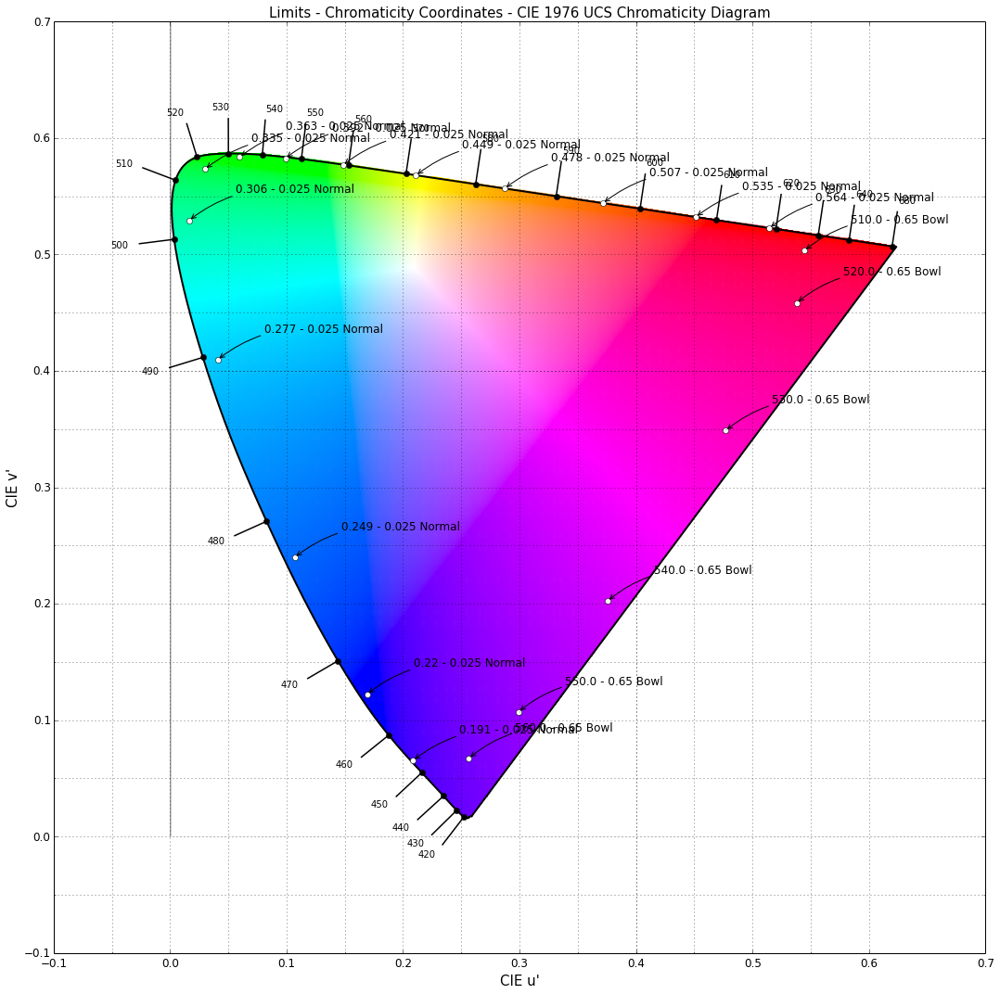

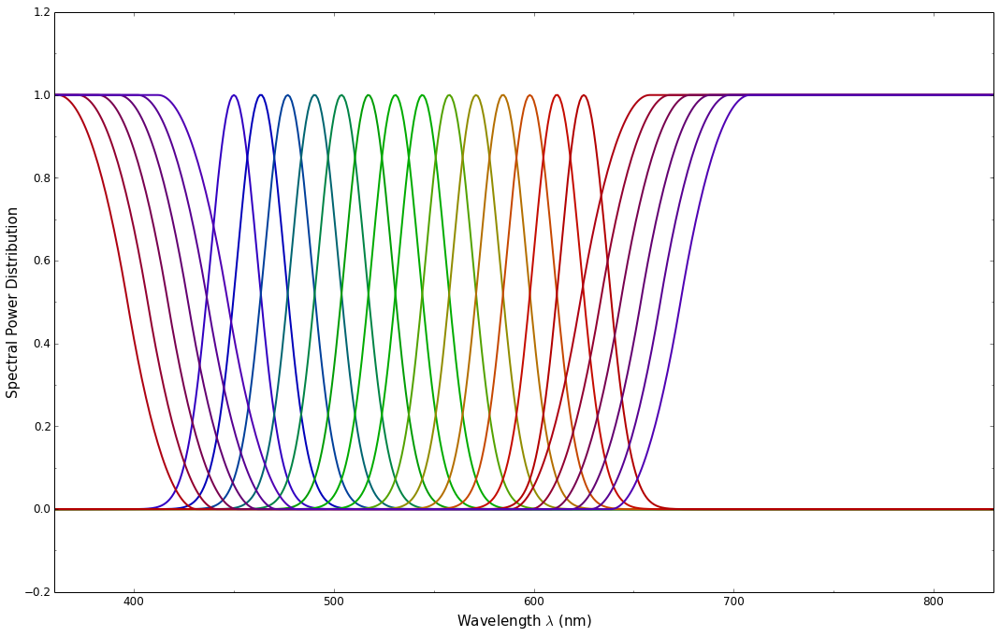

True

In [7]:
from scipy import signal
from scipy.interpolate import interp1d


def roll(a, shift, axis=None):
    # http://stackoverflow.com/a/3153267/931625
    a = np.asanyarray(a)

    if shift == 0:
        return a

    if axis is None:
        n = a.size
        reshape = True
    else:
        n = a.shape[axis]
        reshape = False

    if np.abs(shift) > n:
        array = np.ones_like(a)
    elif shift < 0:
        shift += n
        ones = np.ones_like(a.take(np.arange(n - shift, n), axis))
        array = np.concatenate(
            (ones, a.take(np.arange(n - shift), axis)), axis)
    else:
        ones = np.ones_like(a.take(np.arange(n - shift), axis))
        array = np.concatenate(
            (a.take(np.arange(n - shift, n), axis), ones), axis)
    if reshape:
        return array.reshape(a.shape)
    else:
        return array


def smooth(x, window_size=11, window='bartlett'):
    if x.ndim != 1:
        raise ValueError('Smooth only accepts 1 dimension arrays.')

    if x.size < window_size:
        raise ValueError('Input vector needs to be bigger than window size.')

    if window_size < 3:
        return x

    if not window in ['flat', 'hanning', 'hamming', 'bartlett', 'blackman']:
        raise ValueError(('Window is on of "flat", "hanning", "hamming", '
                          '"bartlett", "blackman"'))

    s = np.r_[x[window_size - 1:0:-1], x, x[-1:-window_size:-1]]

    if window == 'flat':
        w = np.ones(window_size, 'd')
    else:
        w = eval('np.' + window + '(window_size)')

    y = np.convolve(w / w.sum(), s, mode='valid')

    return y[(window_size / 2 - 1):-(window_size / 2)]


def normal_distribution_function(x, mu, sigma):
    return (np.exp(-np.power(x - mu, 2.) /
                   (2 * np.power(sigma, 2.))))


def normal_distribution_spd(mu, sigma, shape):
    samples_count = 100
    samples = np.linspace(0, 1, samples_count)

    filter_samples = normal_distribution_function(samples, mu, sigma)
    filter_data = dict(zip(
        np.linspace(shape.start, shape.end, samples_count), filter_samples))
    filter_spd = colour.SpectralPowerDistribution(
        '{0} - {1} Normal'.format(np.around(mu, 3), np.around(sigma, 3)),
        filter_data)

    return filter_spd.align(shape).normalise()


def square_distribution(frequency, duty):
    samples = np.linspace(0, 1, frequency * 1000, endpoint=False)
    return signal.square(2 * np.pi * frequency * samples, duty)


def bowl_wavelength_spd(shape, wavelength, omega=0.5, sigma=51):
    frequency = 1.5 + (1 - omega) - 0.5

    square_waveform = (square_distribution(frequency, 1 - omega) + 1) / 2

    samples_count = len(square_waveform)
    samples = np.linspace(shape.start, shape.end, samples_count)

    interpolator = colour.LinearInterpolator1d(
        [shape.start, shape.end], [0, samples_count])

    square_waveform = roll(square_waveform,
                           samples_count / 2 + int(interpolator(wavelength)))

    if sigma % 2 == 0:
        sigma += 1

    square_waveform = smooth(square_waveform, window_size=sigma)

    bowl_data = dict(zip(samples, square_waveform))

    bowl_spd = colour.SpectralPowerDistribution(
        '{0} - {1} Bowl'.format(wavelength, omega),
        bowl_data)

    return bowl_spd.align(shape)


def normal_wavelength_spd(shape, wavelength, sigma):
    interpolator = colour.LinearInterpolator1d(
        [shape.start, shape.end], [0, 1])
    return normal_distribution_spd(interpolator(wavelength), sigma, shape)


WAVELENGTH_SPDS = [normal_wavelength_spd(SHAPE, w, 0.025)
                   for w in np.linspace(450, 625, 14)]

LOGGER.info('Wavelengths spds: \'{0}\''.format(
    ', '.join(sorted(spd.name for spd in WAVELENGTH_SPDS))))

BOWL_SPDS = [bowl_wavelength_spd(SHAPE, w, 0.65, 200)
             for w in np.linspace(510, 560, 6)]

LOGGER.info('Bowl spds: \'{0}\''.format(
    ', '.join(sorted(spd.name for spd in BOWL_SPDS))))

CIE_2_1931_SPDS = WAVELENGTH_SPDS + BOWL_SPDS

spds_CIE_1931_chromaticity_diagram_plot(
    CIE_2_1931_SPDS,
    title=('Limits - Chromaticity Coordinates - '
           'CIE 1931 Chromaticity Diagram'))

spds_CIE_1960_UCS_chromaticity_diagram_plot(
    CIE_2_1931_SPDS,
    title=('Limits - Chromaticity Coordinates - '
           'CIE 1960 UCS Chromaticity Diagram'))

spds_CIE_1976_UCS_chromaticity_diagram_plot(
    CIE_2_1931_SPDS,
    title=('Limits - Chromaticity Coordinates - '
           'CIE 1976 UCS Chromaticity Diagram'))

multi_spd_plot(CIE_2_1931_SPDS, use_spds_colours=True, legend=False)

## Random Filters - Design

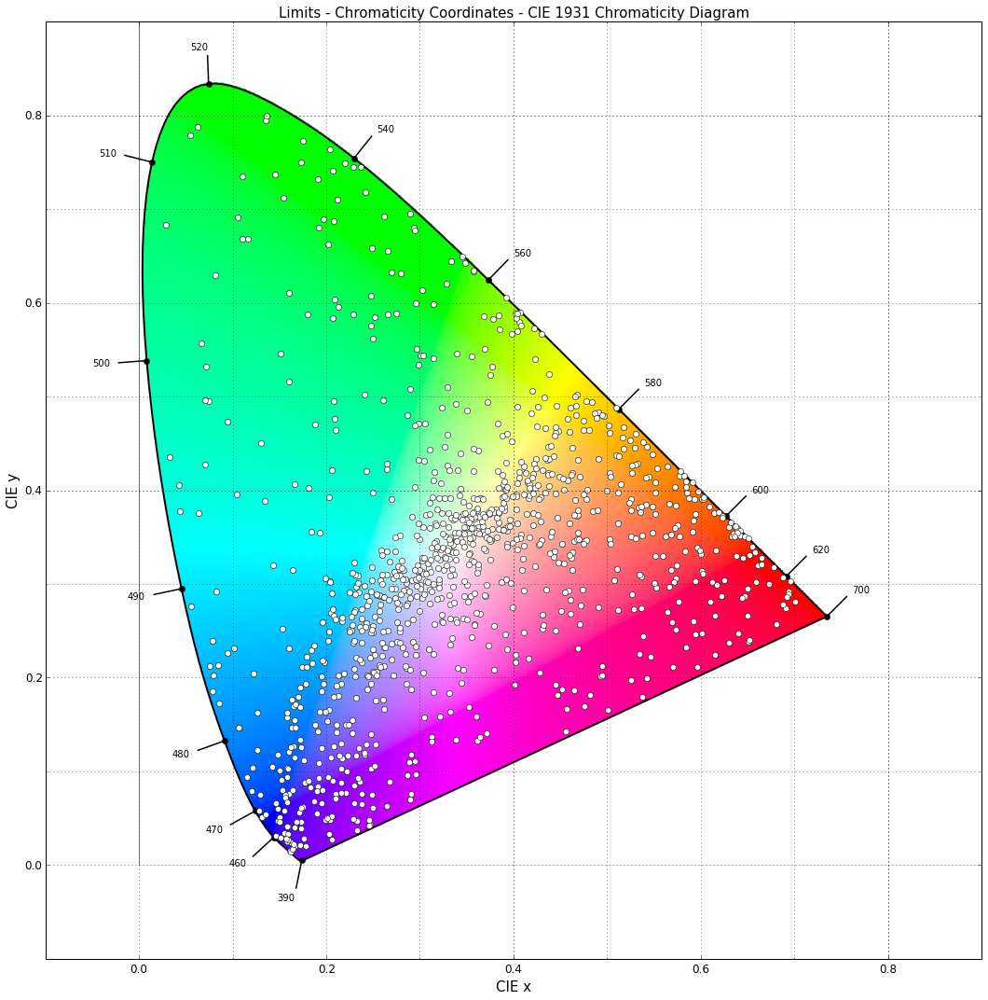

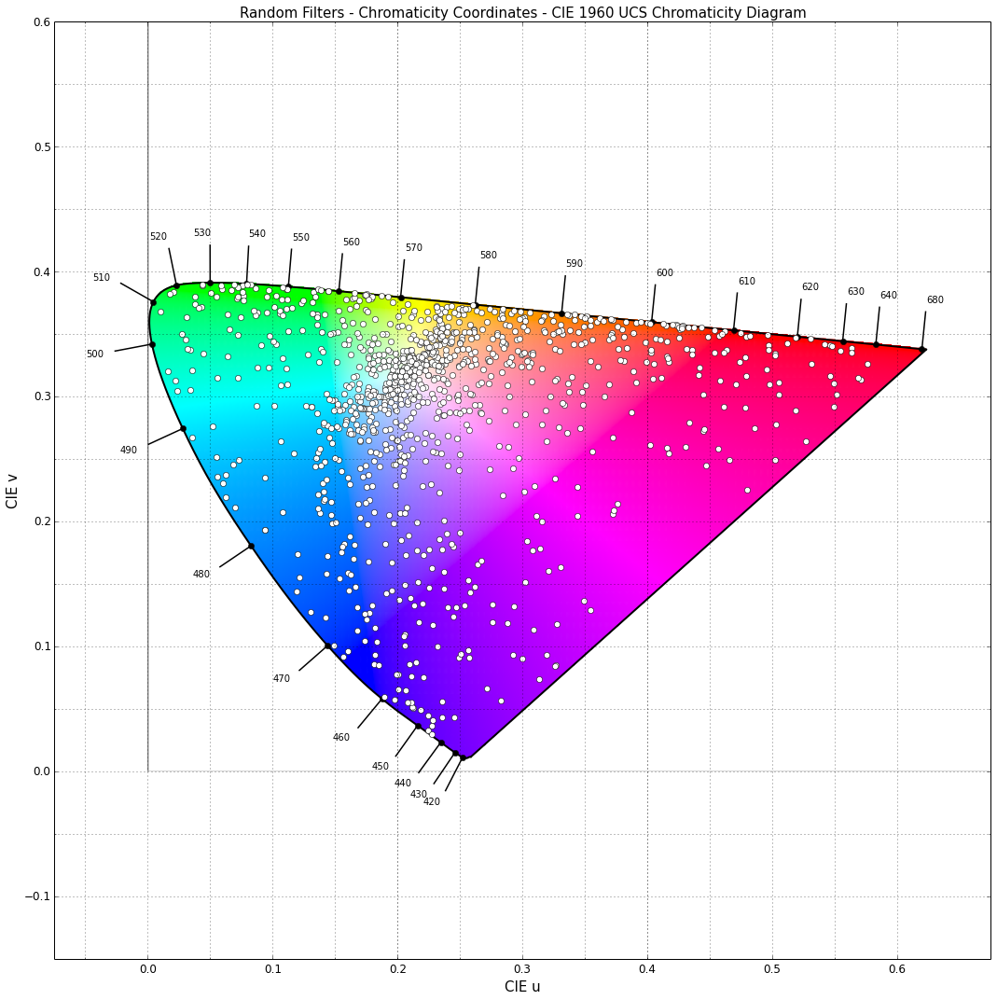

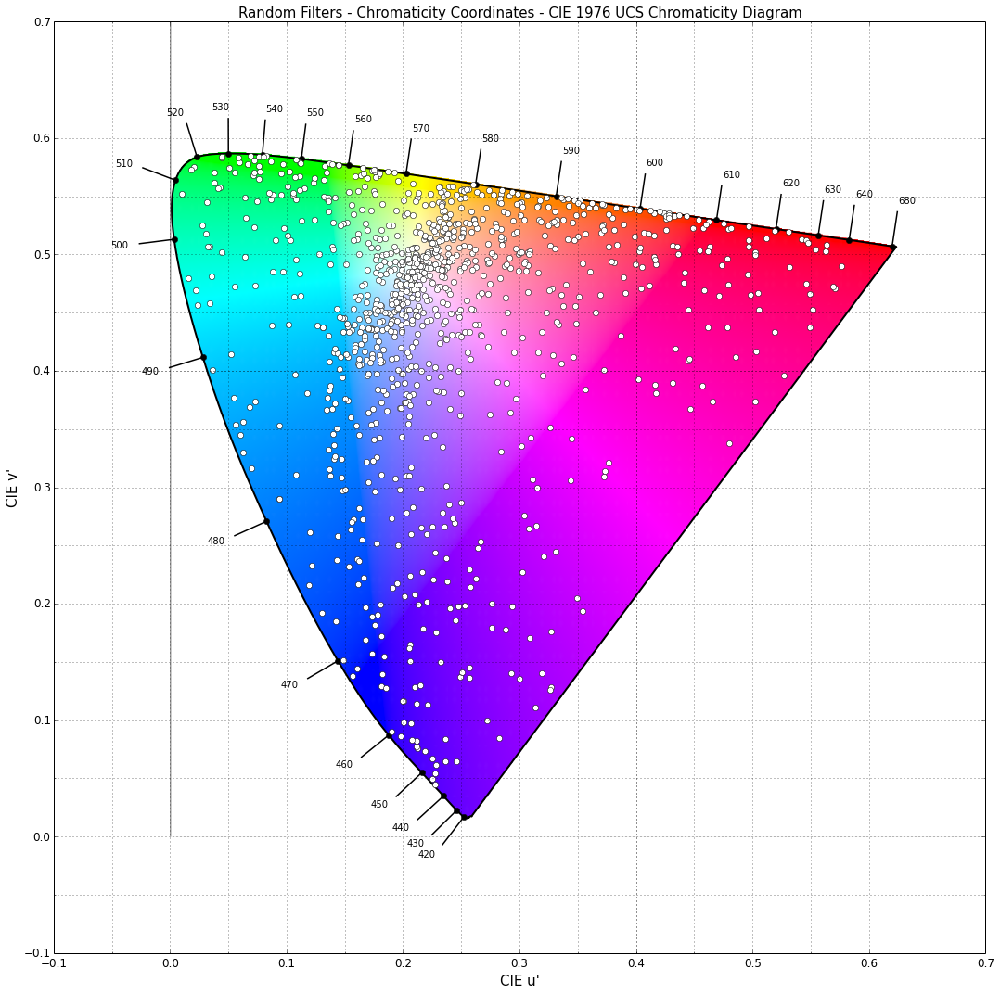

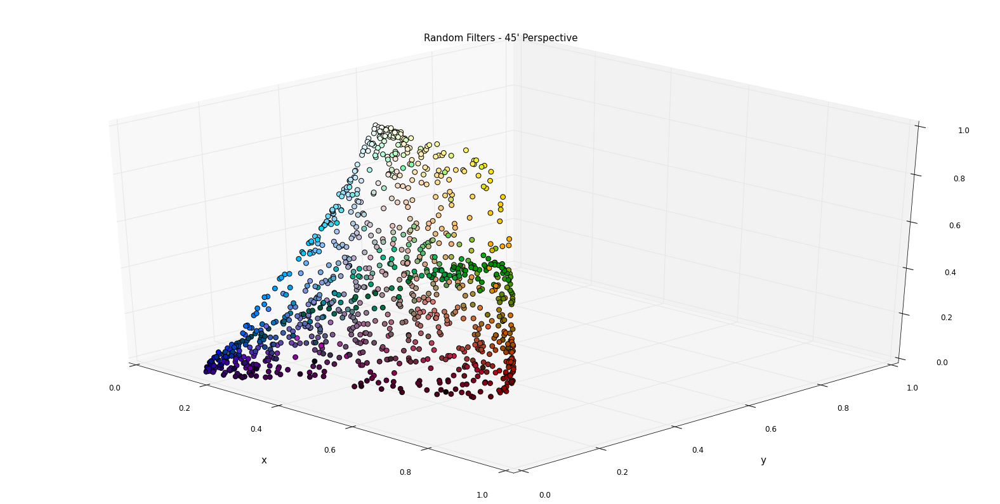

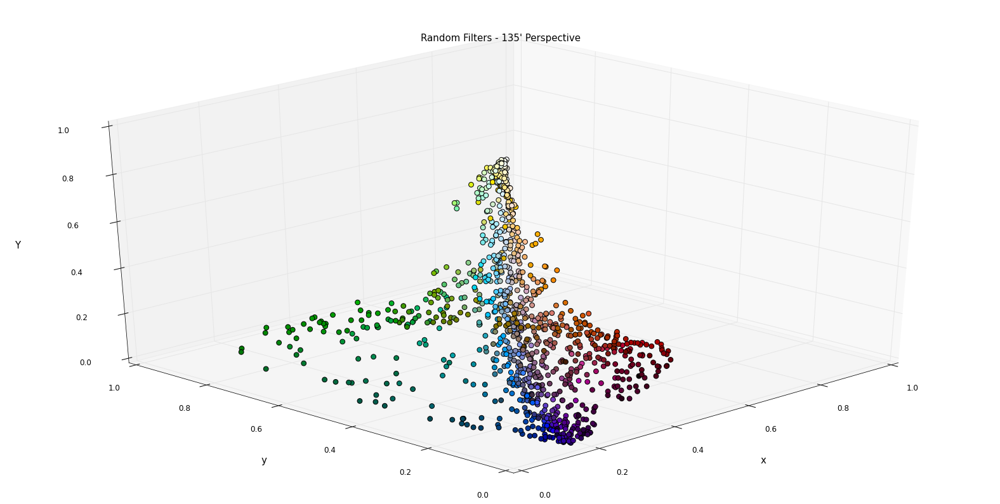

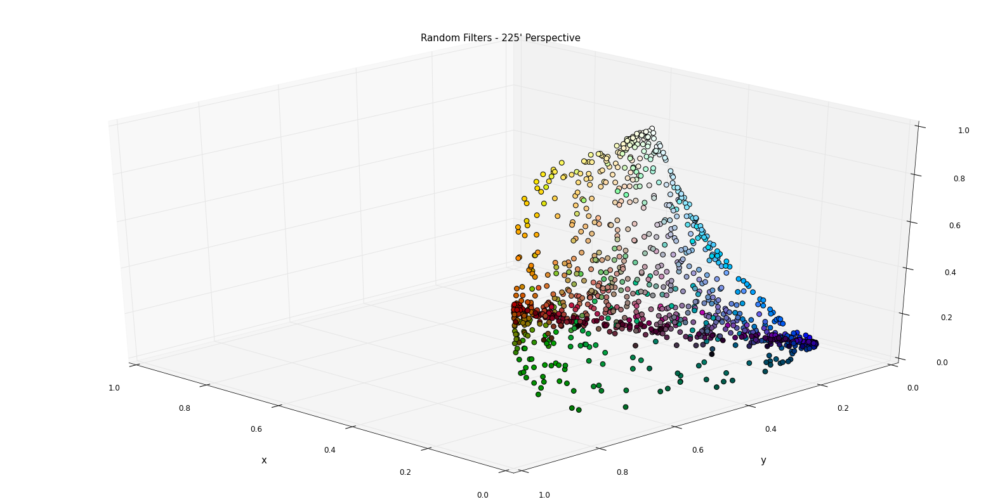

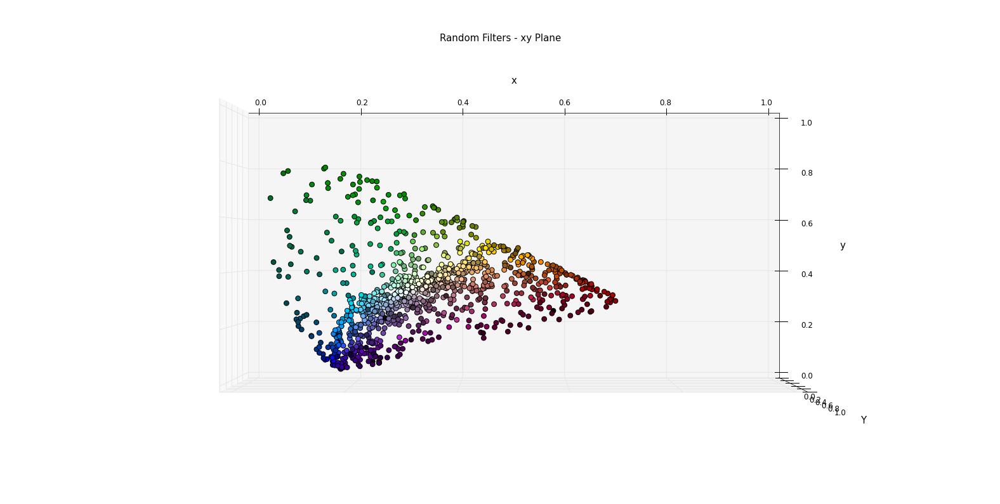

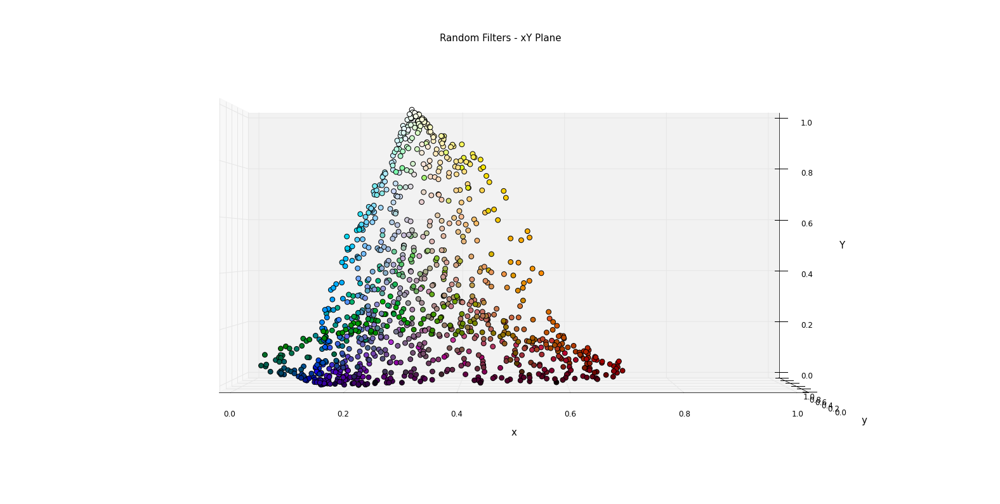

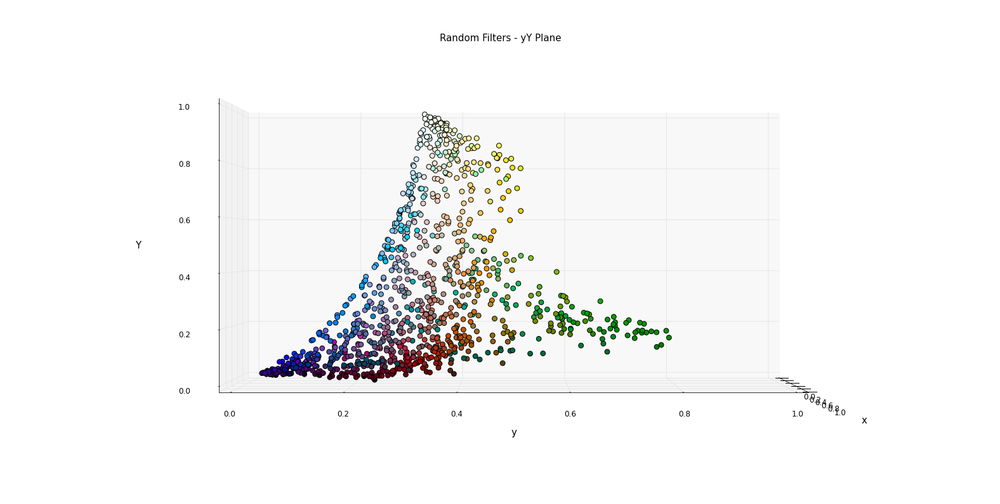

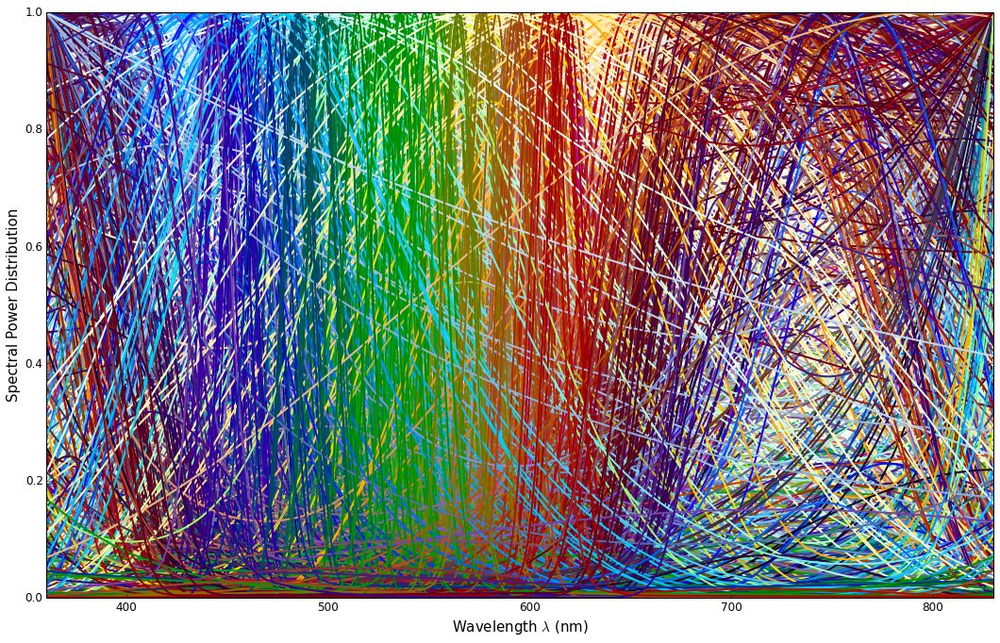

In [8]:
import itertools
from scipy.interpolate import interp1d

# Defining random seed.
np.random.seed(12)


def xyY_3d_plot(xyY, azimuth=None, elevation=None, **kwargs):
    # Disable 3d fog.
    art3d.zalpha = lambda *args: args[0]

    RGB = [np.clip(colour.XYZ_to_sRGB(colour.xyY_to_XYZ(x)), 0, 1)
           for x in xyY]

    figure = matplotlib.pyplot.figure()
    axes = figure.add_subplot(111, projection='3d')
    axes.scatter(xyY[:, 0],
                 xyY[:, 1],
                 xyY[:, 2],
                 c=RGB,
                 s=60)

    axes.view_init(elev=elevation, azim=azimuth)

    axes.set_xlabel('x')
    axes.set_xlim(0, 1)
    axes.set_ylabel('y')
    axes.set_ylim(0, 1)
    axes.set_zlabel('Y')
    axes.set_zlim(0, 1)

    decorate(**kwargs)
    display(**kwargs)


def label_spd(spds, label=None):
    [setattr(spd, 'name', '{0} {1}'.format(label, i) if label else None)
     for i, spd in enumerate(spds)]


def saturate_spd(spd, exponent=2):
    for wavelength, value in spd.items:
        spd[wavelength] = value ** exponent
    return spd.normalise()


def random_distribution_function(samples):
    return np.random.random_sample(samples)


def random_filter_spd(shape, spds_cycle):
    wavelengths = np.linspace(shape.start, shape.end, len(shape))

    filter_samples = random_distribution_function(np.random.randint(3, 6))
    interpolator = interp1d(
        np.linspace(shape.start, shape.end, len(filter_samples)),
        filter_samples,
        kind=2)

    values = interpolator(wavelengths)

    base_spd = next(spds_cycle)
    if base_spd is not None:
        weights = [np.random.sample(), np.random.sample()]
        weights = np.average(np.dstack((weights, [0.15, 0.85])), axis=2)[0]
        base_spd_values = np.roll(base_spd.values, np.random.randint(10) - 10)
        values = np.ravel(np.average(np.dstack((values, base_spd_values)),
                                     axis=2,
                                     weights=weights))

    filter_data = dict(zip(wavelengths, values))
    filter_spd = colour.SpectralPowerDistribution('Random', filter_data)

    minimum = np.min(filter_spd.values)
    if minimum <= 0:
        filter_spd += np.abs(minimum)

    return filter_spd.normalise()


def unique_spds(spds, tolerance=0.1):
    spds_values = np.array([spd.values for spd in spds])

    indexes = {}
    for i, f_x in enumerate(spds_values):
        indexes[i] = []
        for j, f_y in enumerate(spds_values):
            if i == j:
                continue

            if np.allclose(f_x, f_y, rtol=tolerance / 2, atol=tolerance / 2):
                if j not in indexes:
                    indexes[i].append(j)
            
    return [spds[index] for index in sorted(indexes) if not indexes[index]]

CIE_2_1931_SPDS_CYCLE = itertools.cycle(
    [None] * len(CIE_2_1931_SPDS) +
    [spd.clone().align(SHAPE) for spd in CIE_2_1931_SPDS])

BATCH = 400
RANDOM_FILTERS = [random_filter_spd(SHAPE, CIE_2_1931_SPDS_CYCLE)
                  for x in range(BATCH)]

RANDOM_FILTERS += [
    saturate_spd(random_filter_spd(SHAPE, CIE_2_1931_SPDS_CYCLE), 2)
    for x in range(BATCH)]

RANDOM_FILTERS += [
    saturate_spd(random_filter_spd(SHAPE, CIE_2_1931_SPDS_CYCLE), 3)
    for x in range(BATCH)]

LOGGER.info('Random filters count: {0}'.format(len(RANDOM_FILTERS)))

RANDOM_FILTERS = unique_spds(RANDOM_FILTERS, 0.1)

LOGGER.info('Unique random filters count: {0}'.format(len(RANDOM_FILTERS)))

spds_CIE_1931_chromaticity_diagram_plot(
    RANDOM_FILTERS,
    annotate=False,
    title=('Limits - Chromaticity Coordinates - '
           'CIE 1931 Chromaticity Diagram'))

spds_CIE_1960_UCS_chromaticity_diagram_plot(
    RANDOM_FILTERS,
    annotate=False,
    title=('Random Filters - Chromaticity Coordinates - '
           'CIE 1960 UCS Chromaticity Diagram'))

spds_CIE_1976_UCS_chromaticity_diagram_plot(
    RANDOM_FILTERS,
    annotate=False,
    title=('Random Filters - Chromaticity Coordinates - '
           'CIE 1976 UCS Chromaticity Diagram'))

xyY = np.array([colour.XYZ_to_xyY(colour.spectral_to_XYZ(
    spd, illuminant=colour.ILLUMINANTS_RELATIVE_SPDS['D65']) / 100)
                for spd in RANDOM_FILTERS])

xyY_3d_plot(xyY, azimuth=-45, title='Random Filters - 45\' Perspective')
xyY_3d_plot(xyY, azimuth=-135, title='Random Filters - 135\' Perspective')
xyY_3d_plot(xyY, azimuth=-225, title='Random Filters - 225\' Perspective')
xyY_3d_plot(xyY, elevation=90, azimuth=-90, title='Random Filters - xy Plane')
xyY_3d_plot(xyY, elevation=0, azimuth=-90, title='Random Filters - xY Plane')
xyY_3d_plot(xyY, elevation=0, azimuth=360, title='Random Filters - yY Plane')

multi_spd_plot(RANDOM_FILTERS, use_spds_colours=True, legend=False)

label_spd(RANDOM_FILTERS, 'Random')

## $\Delta_{E_{ab}}$ CIE 2000 Colour Difference

In [9]:
from colour.utilities.verbose import message_box

message_box('Random Filters - CIE XYZ')
RANDOM_FILTERS_XYZ = apply_filters(RANDOM_FILTERS)

*                                                                             *
*   Random Filters - CIE XYZ                                                  *
*                                                                             *
'apply_filters' took: 92366.2811 sec


In [10]:
FILTERS_STATISTICS = filters_statistics(RANDOM_FILTERS_XYZ)

'filters_statistics' took: 622.3279 sec


In [11]:
message_box('Random Filters - Delta E')
HTML(html_format_overall_statistics(FILTERS_STATISTICS))

*                                                                             *
*   Random Filters - Delta E                                                  *
*                                                                             *


## Conclusion

We won't provide any conclusions because the results in the context of the tests are self-explanatory.

For specific work in the VFX industry *ACEScc* and *ACEScg* using *ACES Primaries 1* are the best performing RGB colourspace models.

A detailed spreadsheet with the various colour rendition chart results is available at the following URL: http://goo.gl/akrH5m

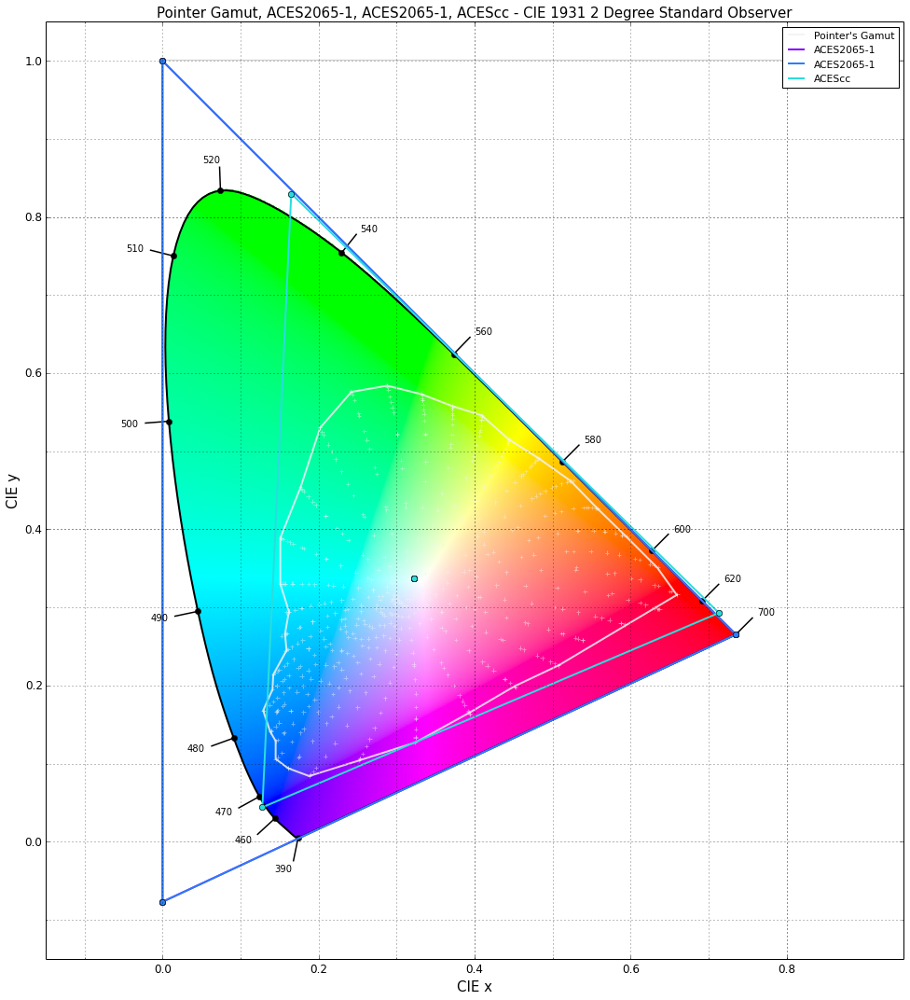

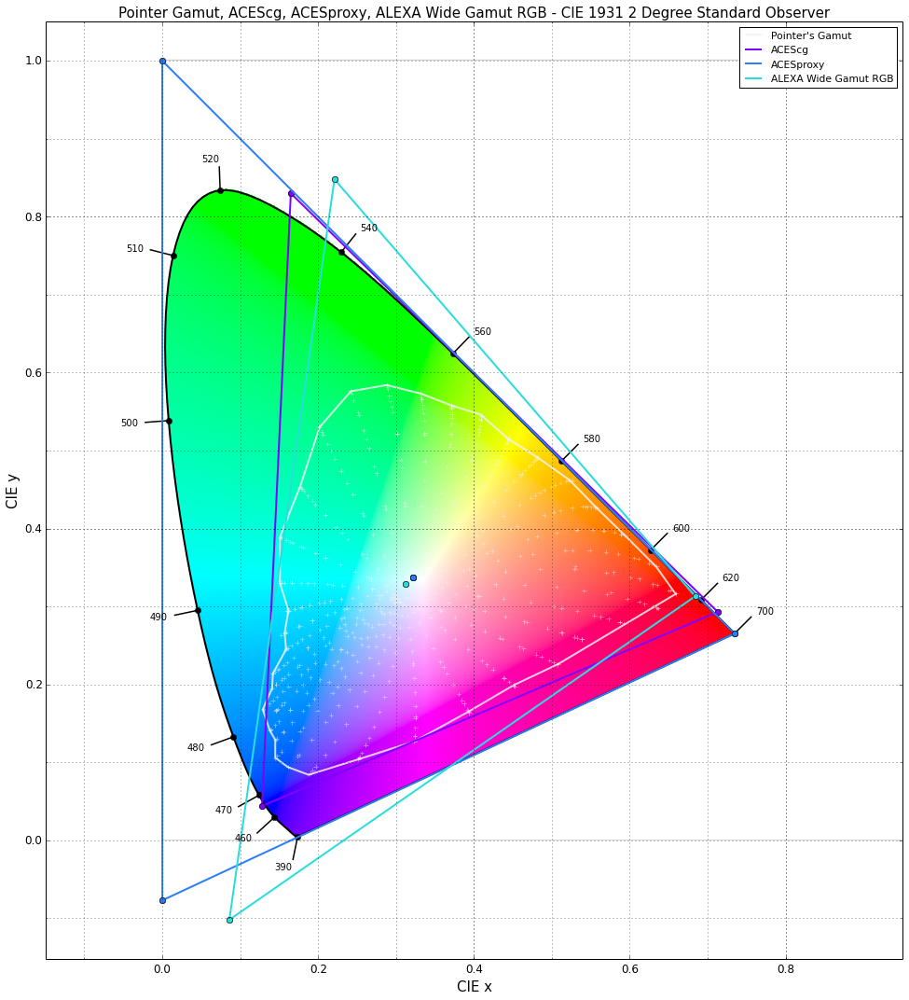

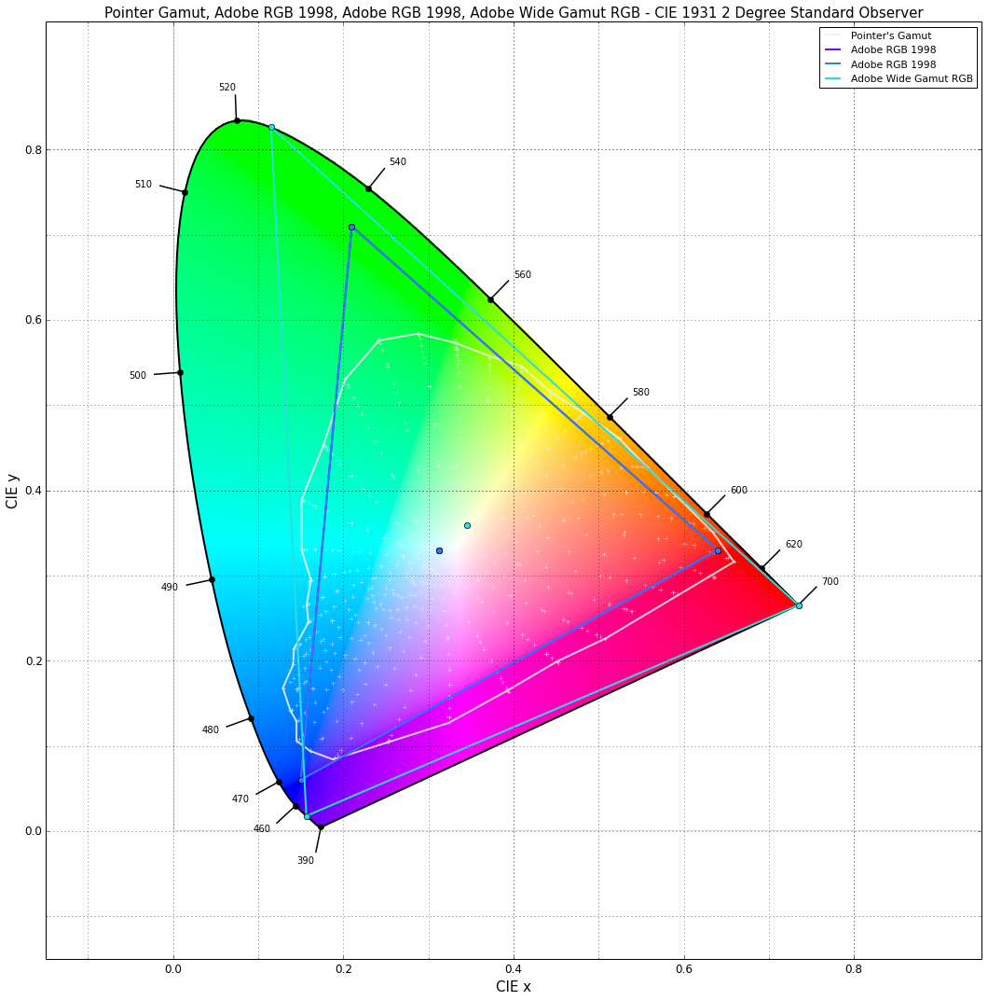

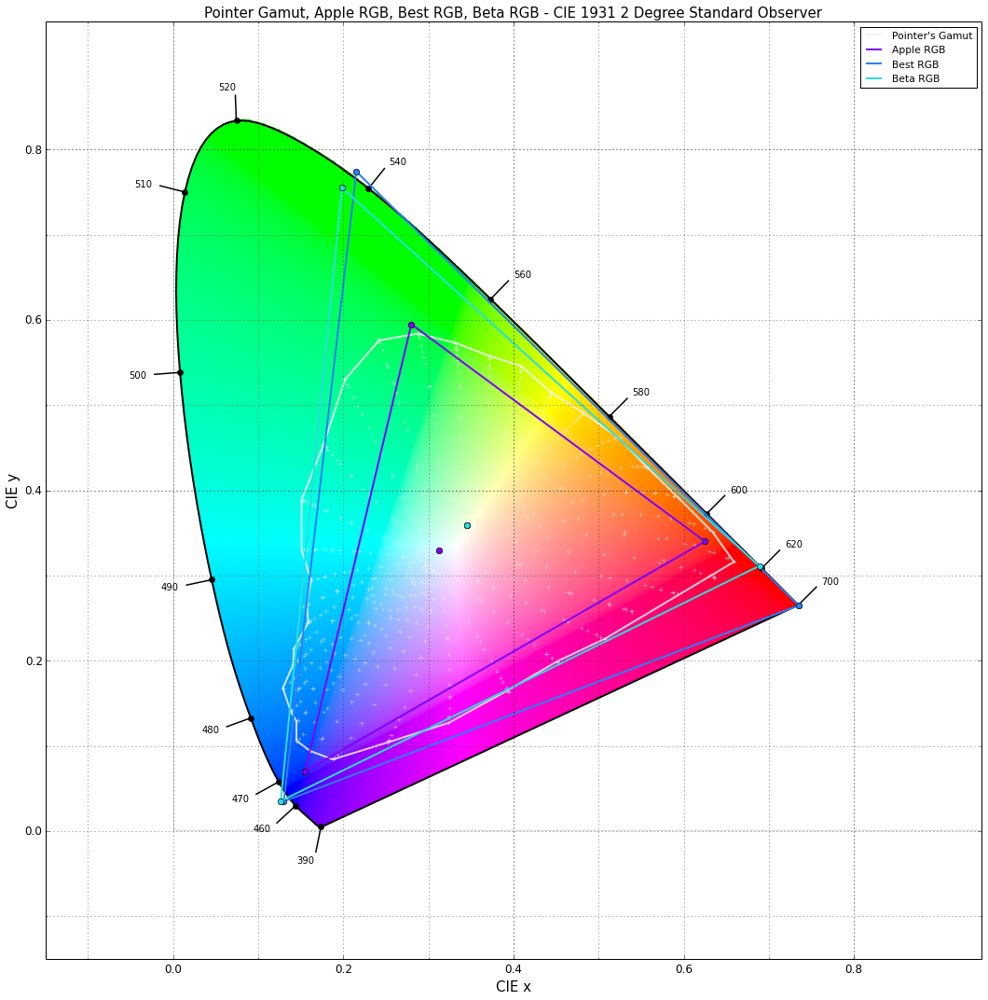

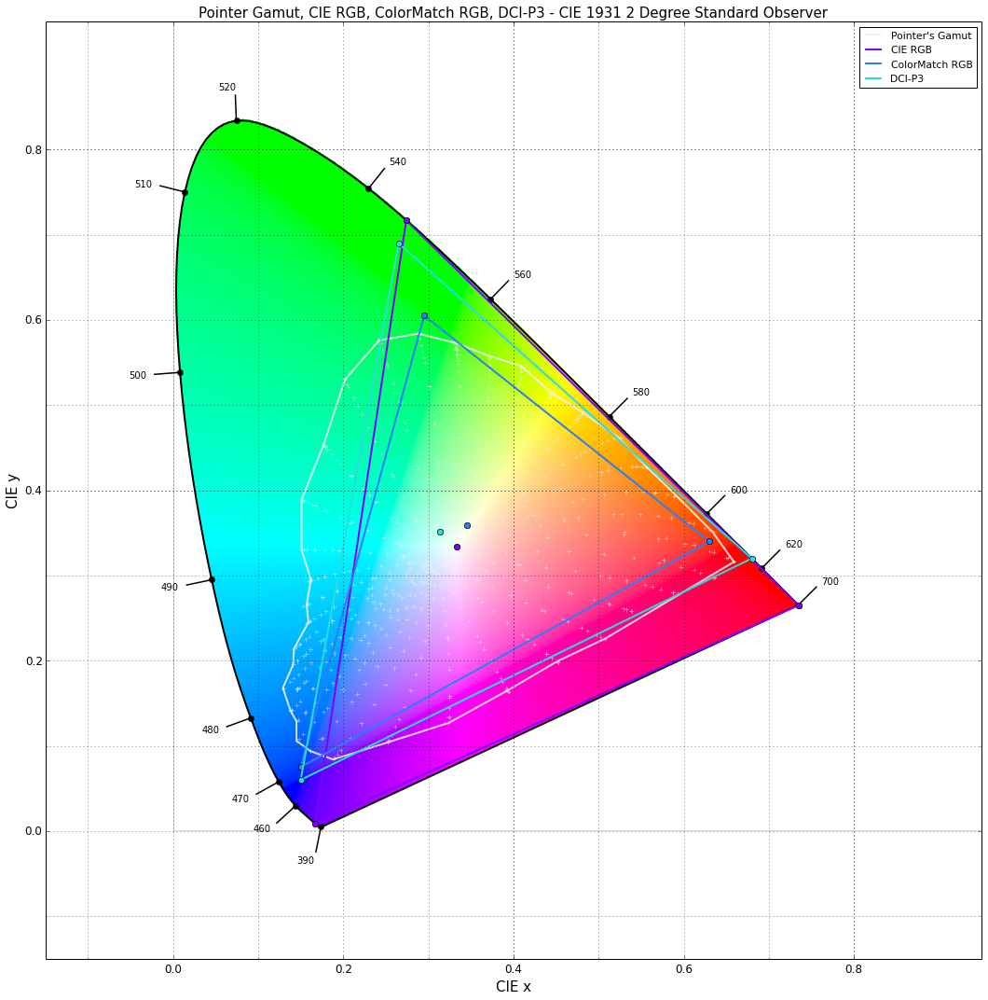

...

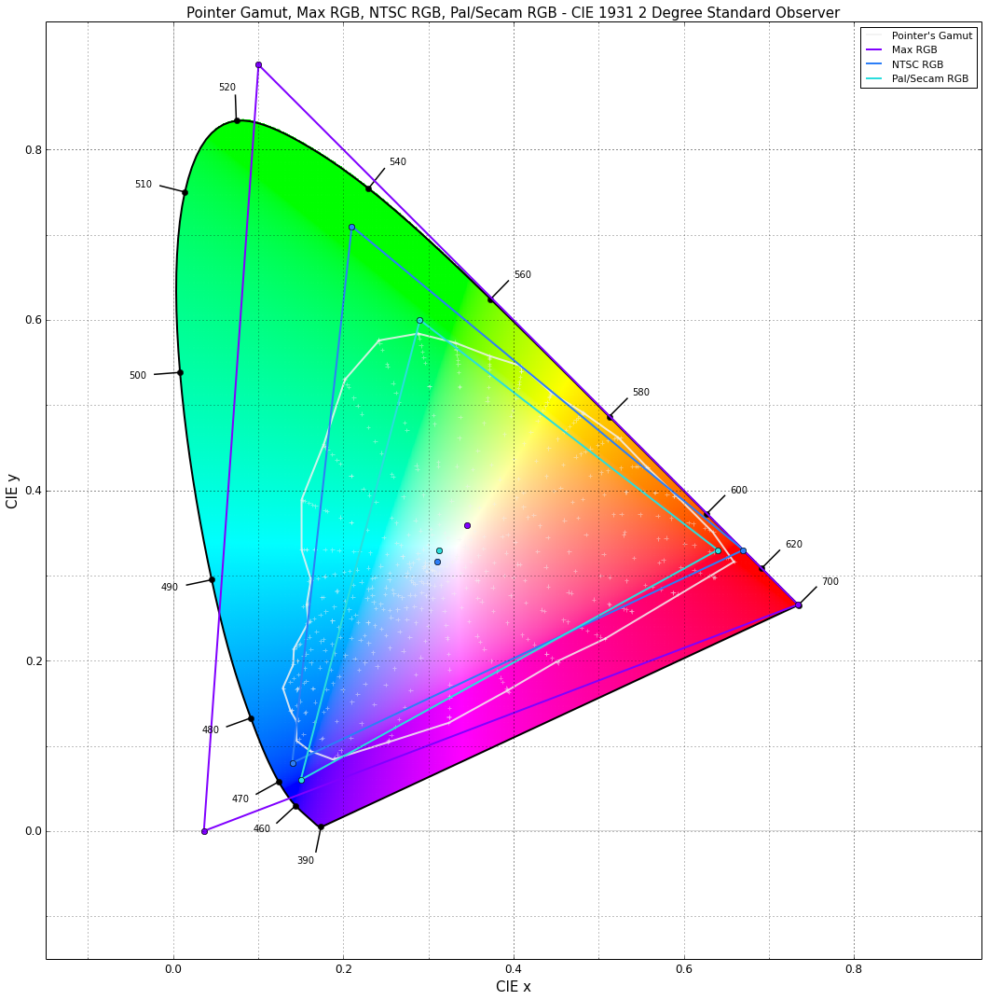

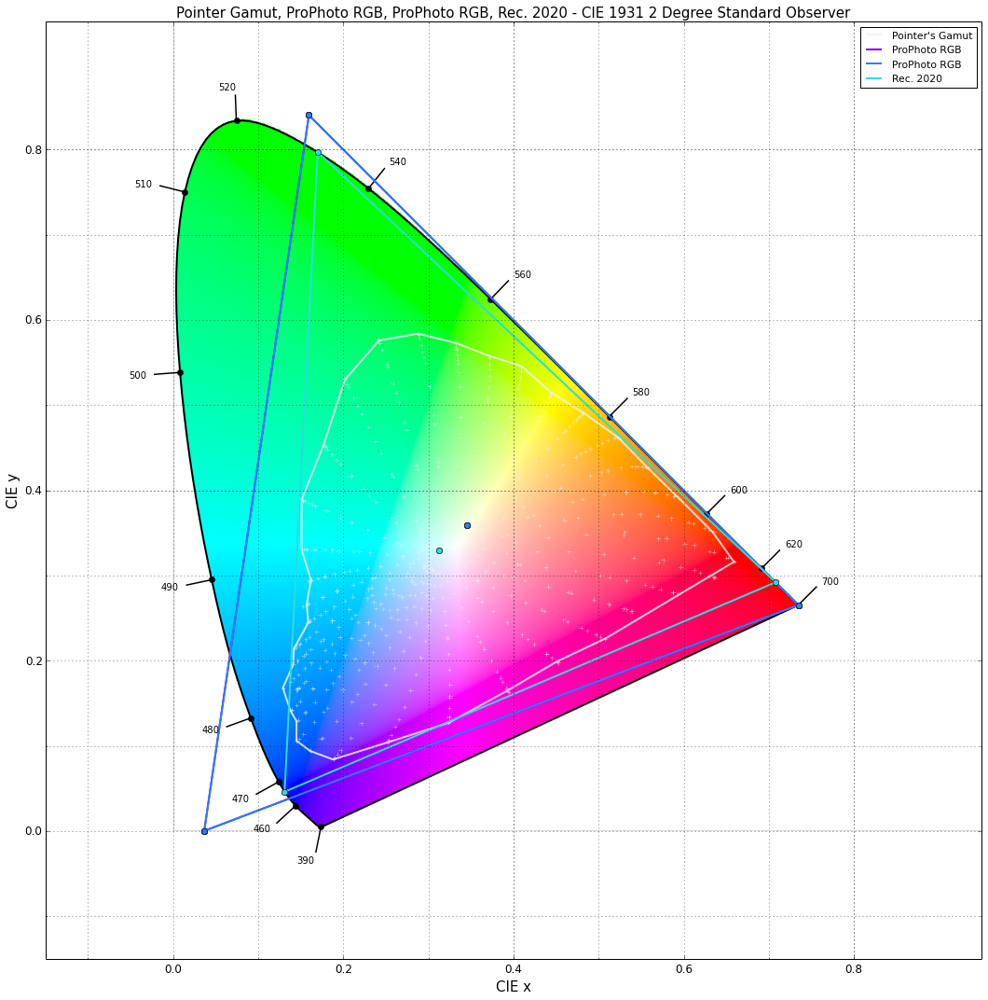

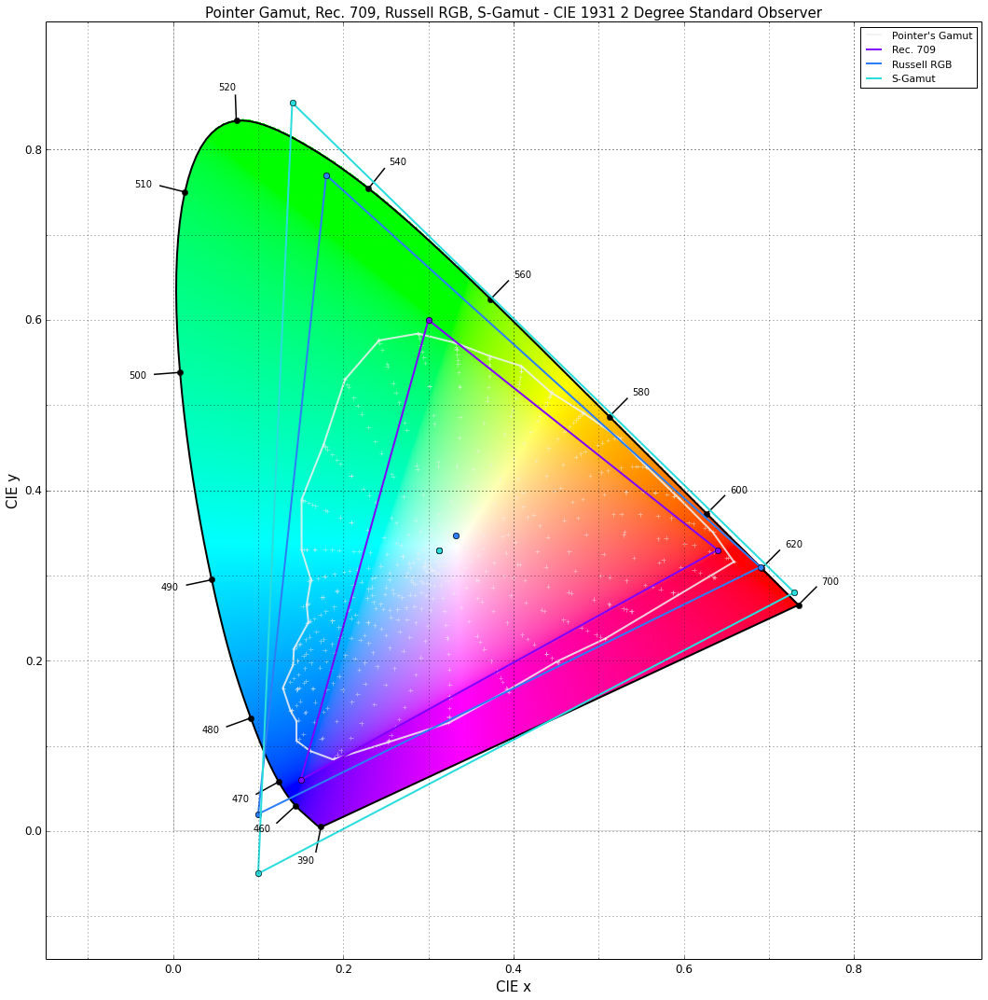

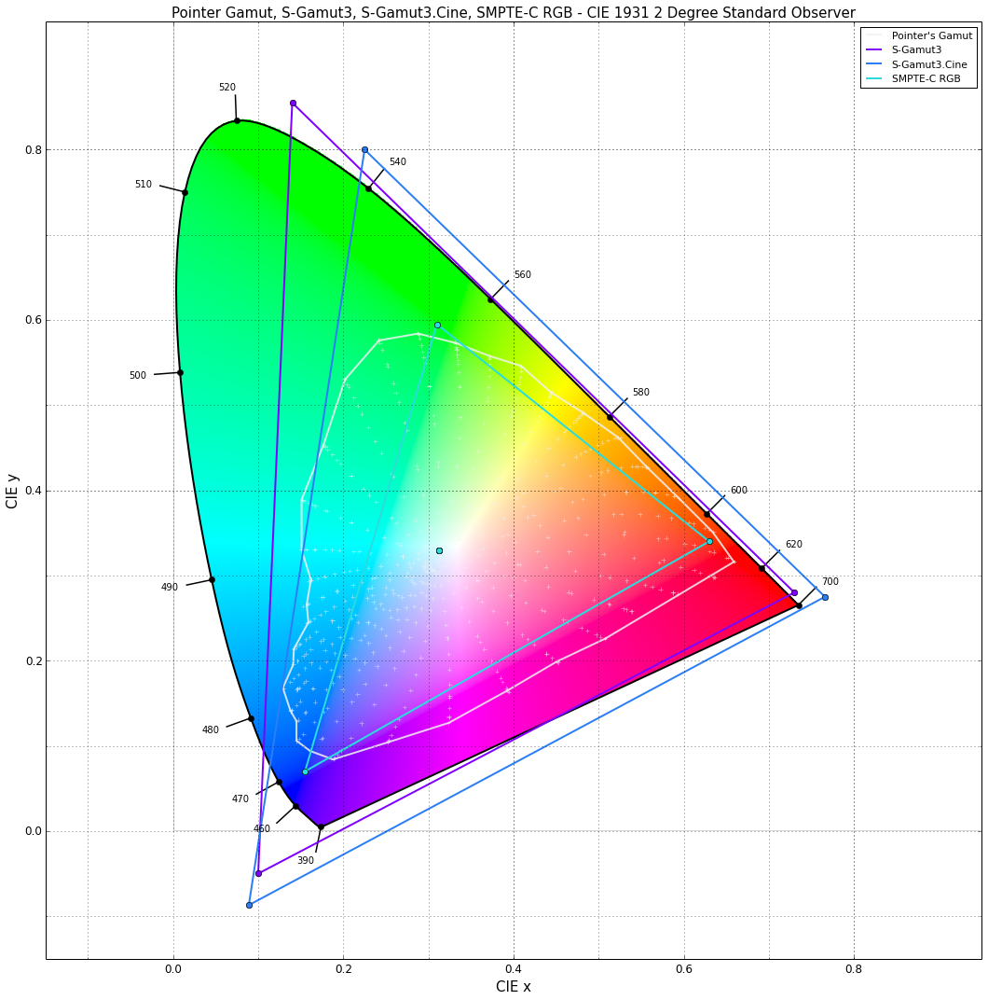

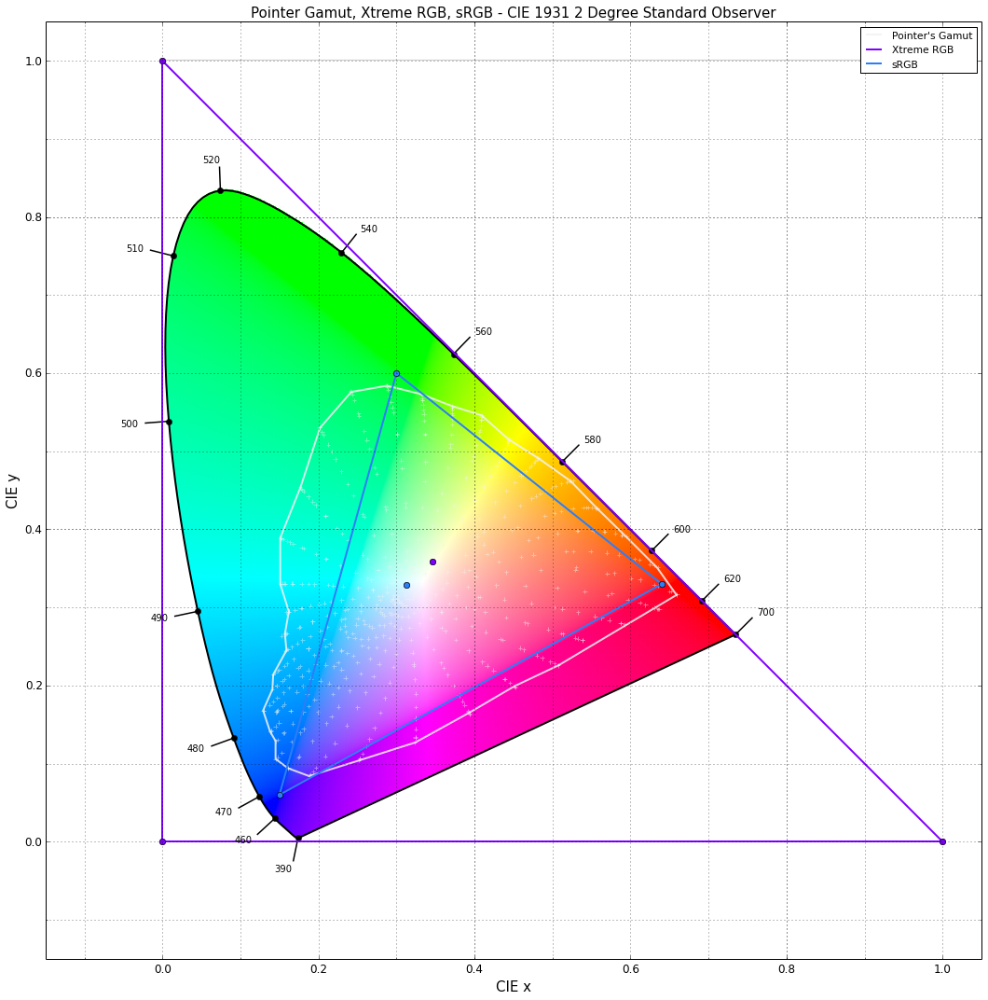

In [12]:
for batch in colour.utilities.batch(sorted([x.name for x in COLOURSPACES_T])):
    colourspaces_CIE_1931_chromaticity_diagram_plot(
        ['Pointer Gamut'] + batch)
LOGGER.info('*' * 79)